# Лабораторная работа 4:  Уровень решения проблемы обработки и генерации естественного языка, ч.4

1. **Нормализация** переиспользуется из `lab_1` (токенизация, стемминг,
   лемматизация, синонимия, стоп-слова);
2. **CNN (TextCNN)** — одномерные свёртки нескольких размеров ядра по матрице
   эмбеддингов слов + max-over-time pooling (Kim, 2014);
3. **RNN (двунаправленный GRU)** — последовательный энкодер, вектор документа —
   конкатенация последних скрытых состояний направлений;
4. **Фасад `NeuralAnalyzer`** — обучение, семантический поиск, близость
   документов, классификация темы и векторы слов;
5. Сравнение с LSA (`lab_2`) и Doc2Vec (`lab_3`) на одних и тех же запросах,
   пользовательский корпус и масштабный пример на отзывах **RuReviews**.

## 1. Постановка задачи

Для набора русскоязычных документов требуется:

- построить **обучаемые нейросетевые представления документов** — CNN (TextCNN) и
  RNN (двунаправленный GRU), обученные **с супервизией** на классификацию тем
  корпуса; вектор документа — предпоследний (пулинговый/скрытый) слой;
- реализовать **семантический поиск** (запрос → ближайшие документы) и
  **близость документов** в пространстве этих представлений;
- показать **классификацию темы** документа (естественное следствие супервизии);
- сравнить новый метод с **LSA** (`lab_2`) и **Doc2Vec** (`lab_3`) на одних и тех
  же запросах;
- продемонстрировать работу на **пользовательских данных** и на подвыборке
  отзывов **RuReviews** (данные `lab_1`).

Ключевое отличие от LSA/Doc2Vec: представление документа вычисляется **свёрточной
или рекуррентной нейросетью** (не матричным разложением и не таблицей векторов
документов), а обучается сквозным градиентным спуском на задаче классификации.

## 2. Окружение и импорт

Пакет `lab_4` лежит в каталоге `lab_4/`; добавляем корень проекта в `sys.path` и
импортируем публичный API `lab_4.src`. Нормализация переиспользуется из `lab_1`
через мост `lab_4.src._lab1`, LSA-анализатор и загрузчики — из `lab_2` через мост
`lab_4.src._lab2`, Doc2Vec — из `lab_3` для сравнительного описания. Модели
реализованы на **PyTorch** (без `gensim`/`sklearn`).

In [1]:
import glob
import os
import sys
from pathlib import Path

import numpy as np

_HERE = Path(os.getcwd())
if _HERE.name == "notebooks":
    _LAB4 = _HERE.parent
elif _HERE.name == "lab_4":
    _LAB4 = _HERE
else:
    _LAB4 = _HERE / "lab_4"
_PROJECT = _LAB4.parent  # /data/Projects/NLP
for _p in (str(_PROJECT), str(_LAB4)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from lab_4.src import NeuralAnalyzer, TextCNN, GRUEncoder  # noqa: E402
from lab_4.src import SemanticAnalyzer, load_text_files, doc_tokens  # noqa: E402
from lab_3.src import DocVecAnalyzer  # noqa: E402

import torch  # noqa: E402
print("Корень проекта:", _PROJECT)
print("PyTorch:", torch.__version__, "| CPU-обучение детерминировано (seed внутри fit).")

Корень проекта: /data/Projects/NLP
PyTorch: 2.8.0+cpu | CPU-обучение детерминировано (seed внутри fit).


## 3. Данные

Демо-корпус — **42 коротких русских документа по 6 темам** (finance 7, food 7,
health 7, sport 7, tech 7, travel 7) из `lab_2/data/sample_docs/`. Тема документа
выводится из префикса имени файла (до первого `_`). Пользовательский корпус —
**20 документов по 4 темам** (auto, edu, fashion, music) из
`lab_2/data/custom_corpus/`. Разметка тем используется как супервизия.

In [2]:
demo_dir = _PROJECT / "lab_2" / "data" / "sample_docs"
demo_paths = sorted(glob.glob(str(demo_dir / "*.txt")))
demo_texts = load_text_files(demo_paths)
demo_names = [Path(p).name for p in demo_paths]
print("демо-корпус:", len(demo_texts), "документов,",
      sorted(set(n.split("_")[0] for n in demo_names)), "тем")

custom_dir = _PROJECT / "lab_2" / "data" / "custom_corpus"
custom_paths = sorted(glob.glob(str(custom_dir / "*.txt")))
custom_texts = load_text_files(custom_paths)
custom_names = [Path(p).name for p in custom_paths]
print("пользовательский корпус:", len(custom_texts), "документов,",
      sorted(set(n.split("_")[0] for n in custom_names)), "темы")

# Пример нормализации одного документа (канонические токены: лемма + синонимы без стоп-слов)
print("токены demo[0]:", doc_tokens(demo_texts[0], "canonical")[:12], "...")

демо-корпус: 42 документов, ['finance', 'food', 'health', 'sport', 'tech', 'travel'] тем
пользовательский корпус: 20 документов, ['auto', 'edu', 'fashion', 'music'] темы
токены demo[0]: ['банк', 'предложить', 'клиент', 'вклад', 'повышенный', 'ставка', 'первый', 'год', 'процент', 'начисляться', 'ежемесячно', 'снять'] ...


## 4. CNN (TextCNN): обучение на демо-корпусе

Обучаем `TextCNN`: матрица эмбеддингов слов → параллельные свёртки с ядрами
`(3, 4, 5)` → ReLU → max-pool по времени (с маской по длине документа) →
конкатенация → классификатор на 6 тем. Вектор документа — конкатенация
max-pooled карт признаков (размерность `num_filters × len(kernel_sizes)`).

In [3]:
cnn = NeuralAnalyzer(str(_PROJECT / "lab_4" / "src" / "models" / "cnn_demo"), method="cnn")
cnn_stats = cnn.fit(
    demo_texts,
    sources=demo_names,
    embedding_dim=64,
    num_filters=64,
    kernel_sizes=(3, 4, 5),
    epochs=40,
    learning_rate=1e-3,
    batch_size=8,
    max_len=48,
    seed=42,
)
cnn_stats

{'n_docs': 42,
 'n_features': 666,
 'n_classes': 6,
 'dim': 192,
 'method': 'cnn',
 'epochs': 40,
 'accuracy': 1.0,
 'seconds': 2.337221990339458}

### Семантический поиск «своими словами» (CNN)

Запросы не совпадают с текстами дословно — анализатор находит документы по смыслу
через косинусную близость векторов-представлений.

In [4]:
for q in [
    "Футбольный матч и тренировка команды на стадионе",
    "Новый ноутбук с мощным процессором и большим экраном",
    "Как приготовить вкусный суп из свежих овощей",
]:
    print("Q:", q)
    for m in cnn.query(q, top_n=2):
        print("   ", round(m.score, 3), m.source)
    print("   predict:", cnn.predict(q).label)

Q: Футбольный матч и тренировка команды на стадионе
    0.847 sport_07.txt
    0.838 sport_06.txt
   predict: sport
Q: Новый ноутбук с мощным процессором и большим экраном
    0.81 tech_01.txt
    0.769 tech_05.txt
   predict: tech
Q: Как приготовить вкусный суп из свежих овощей
    0.781 travel_05.txt
    0.776 travel_04.txt
   predict: food


## 5. RNN (двунаправленный GRU): обучение на демо-корпусе

Обучаем `GRUEncoder`: `pack_padded_sequence` корректно игнорирует паддинг, вектор
документа — конкатенация последних скрытых состояний вперёд/назад (размерность
`2 × hidden_dim`). LSTM не используется.

In [5]:
rnn = NeuralAnalyzer(str(_PROJECT / "lab_4" / "src" / "models" / "rnn_demo"), method="rnn")
rnn_stats = rnn.fit(
    demo_texts,
    sources=demo_names,
    embedding_dim=64,
    hidden_dim=64,
    num_layers=1,
    bidirectional=True,
    epochs=40,
    learning_rate=1e-3,
    batch_size=8,
    max_len=48,
    seed=42,
)
rnn_stats

{'n_docs': 42,
 'n_features': 666,
 'n_classes': 6,
 'dim': 128,
 'method': 'rnn',
 'epochs': 40,
 'accuracy': 1.0,
 'seconds': 4.10864877467975}

### Семантический поиск «своими словами» (GRU)

In [6]:
for q in [
    "Футбольный матч и тренировка команды на стадионе",
    "Новый ноутбук с мощным процессором и большим экраном",
    "Как приготовить вкусный суп из свежих овощей",
]:
    print("Q:", q)
    for m in rnn.query(q, top_n=2):
        print("   ", round(m.score, 3), m.source)
    print("   predict:", rnn.predict(q).label)

Q: Футбольный матч и тренировка команды на стадионе
    0.843 sport_01.txt
    0.79 sport_05.txt
   predict: sport
Q: Новый ноутбук с мощным процессором и большим экраном
    0.561 tech_02.txt
    0.559 tech_01.txt
   predict: tech
Q: Как приготовить вкусный суп из свежих овощей
    0.38 tech_04.txt
    0.361 tech_07.txt
   predict: tech


## 6. Близость документов и словесная семантика

`similar` возвращает ближайших соседей документа в пространстве представлений;
`most_similar` — ближайшие слова по обученной матрице эмбеддингов.

In [7]:
print("similar(0) — finance_01.txt (CNN):")
for m in cnn.similar(0, top_n=6, exclude_self=True):
    print("   ", round(m.score, 3), m.source)

print("\nmost_similar('матч') — CNN:")
print("   ", [(w, round(s, 2)) for w, s in cnn.most_similar("матч", top_n=5)])
print("most_similar('матч') — GRU:")
print("   ", [(w, round(s, 2)) for w, s in rnn.most_similar("матч", top_n=5)])
print("most_similar('футбол') — OOV:", cnn.most_similar("футбол"))

similar(0) — finance_01.txt (CNN):
    0.952 finance_05.txt
    0.949 finance_03.txt
    0.947 finance_04.txt
    0.945 finance_02.txt
    0.945 finance_07.txt
    0.941 finance_06.txt

most_similar('матч') — CNN:
    [('лекарство', 0.32), ('стойка', 0.31), ('гулять', 0.28), ('хоккеист', 0.26), ('диск', 0.26)]
most_similar('матч') — GRU:
    [('лекарство', 0.32), ('стойка', 0.31), ('хоккеист', 0.28), ('срок', 0.27), ('гулять', 0.26)]
most_similar('футбол') — OOV: []


## 7. Классификация темы (`predict`)

Супервизия даёт естественный побочный результат — классификатор темы. На
обучающих документах тема определяется верно (точность на демо-корпусе = 1.0 —
маленький корпус запоминается); для коротких запросов «своими словами» softmax
может быть плохо откалиброван — это честное ограничение малого корпуса.

In [8]:
for i in [0, 7, 14, 21, 28, 35]:
    p = cnn.predict(i)
    print(demo_names[i], "->", p.label)

finance_01.txt -> finance
food_01.txt -> food
health_01.txt -> health
sport_01.txt -> sport
tech_01.txt -> tech
travel_01.txt -> travel


## 8. Сравнение с LSA (`lab_2`) и Doc2Vec (`lab_3`) на общих запросах

Загружаем готовые модели LSA и Doc2Vec **без переобучения** и прогоняем один и тот
же набор запросов через три анализатора. Тема документа выводится из его метки.

In [9]:
lsa = SemanticAnalyzer(str(_PROJECT / "lab_2" / "src" / "models" / "lsa_demo"))
d2v = DocVecAnalyzer(str(_PROJECT / "lab_3" / "src" / "models" / "d2v_demo"))

queries = [
    "Игроки вышли на поле и боролись за победу в важном турнире",
    "Мама положила в кастрюлю овощи и поставила на плиту готовиться обед",
    "Программист обновил систему и ускорил работу устройства",
    "Туристы забронировали номер и купили билеты на поезд заранее",
    "Пациент жалуется на боль и слабость, нужен осмотр врача",
    "Он вложил сбережения, чтобы получить прибыль через год",
]
expected = ["sport", "food", "tech", "travel", "health", "finance"]

def topic_of(match):
    return match.source.split("_")[0]

print(f"{'запрос':42s} | {'ожид':6s} | {'LSA':6s} | {'Doc2Vec':7s} | {'CNN':6s} | {'GRU':6s}")
for q, exp in zip(queries, expected):
    l = topic_of(lsa.query(q, top_n=1)[0])
    d = topic_of(d2v.query(q, top_n=1)[0])
    c = topic_of(cnn.query(q, top_n=1)[0])
    r = topic_of(rnn.query(q, top_n=1)[0])
    print(f"{q[:42]:42s} | {exp:6s} | {l:6s} | {d:7s} | {c:6s} | {r:6s}")

for name, analyzer in [("LSA", lsa), ("Doc2Vec", d2v), ("CNN", cnn), ("GRU", rnn)]:
    agree = sum(topic_of(analyzer.query(q, top_n=1)[0]) == exp for q, exp in zip(queries, expected))
    print(name, "top-1 agreement:", agree, "/", len(queries))

запрос                                     | ожид   | LSA    | Doc2Vec | CNN    | GRU   
Игроки вышли на поле и боролись за победу  | sport  | sport  | sport   | sport  | sport 
Мама положила в кастрюлю овощи и поставила | food   | food   | sport   | travel | food  
Программист обновил систему и ускорил рабо | tech   | tech   | tech    | tech   | tech  
Туристы забронировали номер и купили билет | travel | travel | travel  | travel | tech  
Пациент жалуется на боль и слабость, нужен | health | health | health  | health | health
Он вложил сбережения, чтобы получить прибы | finance | finance | finance | tech   | health
LSA top-1 agreement: 6 / 6


Doc2Vec top-1 agreement: 5 / 6
CNN top-1 agreement: 4 / 6
GRU top-1 agreement: 4 / 6


## 9. Пользовательские данные

Тот же конвейер на пользовательском корпусе (20 документов по 4 темам: музыка,
автомобили, образование, мода). Достаточно положить свои `.txt`-файлы (по файлу на
документ) в каталог и обучить.

In [10]:
cnn_custom = NeuralAnalyzer(str(_PROJECT / "lab_4" / "src" / "models" / "cnn_custom"), method="cnn")
cnn_custom.fit(custom_texts, sources=custom_names, embedding_dim=64, num_filters=64,
               kernel_sizes=(3, 4, 5), epochs=40, learning_rate=1e-3, batch_size=8,
               max_len=48, seed=42)

rnn_custom = NeuralAnalyzer(str(_PROJECT / "lab_4" / "src" / "models" / "rnn_custom"), method="rnn")
rnn_custom.fit(custom_texts, sources=custom_names, embedding_dim=64, hidden_dim=64,
               num_layers=1, epochs=40, learning_rate=1e-3, batch_size=8,
               max_len=48, seed=42)

for q in ["Новый альбом и живой концерт популярной группы",
          "Двигатель и коробка передач автомобиля"]:
    print("Q:", q)
    for m in cnn_custom.query(q, top_n=2):
        print("   CNN", round(m.score, 3), m.source)
    for m in rnn_custom.query(q, top_n=2):
        print("   GRU", round(m.score, 3), m.source)

Q: Новый альбом и живой концерт популярной группы
   CNN 0.765 music_04.txt
   CNN 0.763 music_03.txt
   GRU 0.418 auto_04.txt
   GRU 0.338 auto_01.txt
Q: Двигатель и коробка передач автомобиля
   CNN 0.659 auto_01.txt
   CNN 0.658 auto_05.txt
   GRU 0.52 auto_02.txt
   GRU 0.446 auto_04.txt


## 10. Масштаб на отзывах RuReviews (данные `lab_1`)

Тот же конвейер применяется к **сбалансированной подвыборке из 2000 отзывов**
(по ~667 на класс negative/neutral/positive); метки — тональность из `lab_1`.

In [11]:
from collections import defaultdict
from lab_1.src.data import load_corpus

rows = load_corpus(str(_PROJECT / "lab_1" / "data" / "rureviews.csv"))
by_class = defaultdict(list)
for label, text in rows:
    by_class[label].append(text)
per_class = 2000 // len(by_class)
reviews, review_labels = [], []
for label, docs in by_class.items():
    reviews.extend(docs[:per_class])
    review_labels.extend([label] * per_class)
print("отзывов:", len(reviews), "классы:", sorted(set(review_labels)))

cnn_rev = NeuralAnalyzer(str(_PROJECT / "lab_4" / "src" / "models" / "cnn_rureviews"), method="cnn")
cnn_rev.fit(reviews, labels=review_labels, embedding_dim=64, num_filters=64,
            kernel_sizes=(3, 4, 5), epochs=10, learning_rate=1e-3, batch_size=32,
            max_len=48, seed=42)

rnn_rev = NeuralAnalyzer(str(_PROJECT / "lab_4" / "src" / "models" / "rnn_rureviews"), method="rnn")
rnn_rev.fit(reviews, labels=review_labels, embedding_dim=64, hidden_dim=64,
            num_layers=1, epochs=10, learning_rate=1e-3, batch_size=32,
            max_len=48, seed=42)

q = "Куртка оказалась мала, пришлось возвращать, но доставка быстрая"
print("Q:", q)
for m in cnn_rev.query(q, top_n=2):
    print("   CNN", round(m.score, 3), m.source, "—", m.text[:60])

отзывов: 1998 классы: ['negative', 'neutral', 'positive']


Q: Куртка оказалась мала, пришлось возвращать, но доставка быстрая
   CNN 0.869 doc_652 — еслиб я знала что будет такое отличие я бы не заказывала. уж
   CNN 0.869 doc_749 — Куртка шла долго. Устала ждать. В итоге пришла с браком. При


## 11. 2D-проекция векторов документов

Проецируем матрицу векторов документов CNN на первые две главные компоненты
(усечённое SVD центрированной матрицы) и раскрашиваем по темам.

In [12]:
os.environ.setdefault("MPLCONFIGDIR", "/tmp/mplconfig_lab4")
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

doc_vecs = np.vstack([cnn.doc_vector(i) for i in range(cnn.n_docs)]).astype(np.float64)
centered = doc_vecs - doc_vecs.mean(axis=0)
u, s, vt = np.linalg.svd(centered, full_matrices=False)
proj = centered @ vt[:2].T
explained = (s[:2] ** 2 / (s ** 2).sum()).tolist()

topics = [n.split("_")[0] for n in demo_names]
color_map = {t: f"C{i}" for i, t in enumerate(sorted(set(topics)))}

plt.figure(figsize=(9, 7))
for t in sorted(set(topics)):
    idx = [i for i, tt in enumerate(topics) if tt == t]
    plt.scatter(proj[idx, 0], proj[idx, 1], c=color_map[t], label=t, s=60)
    for i in idx:
        plt.annotate(demo_names[i], (proj[i, 0], proj[i, 1]), fontsize=7, alpha=0.75)
plt.legend()
plt.title(f"CNN: документы демо-корпуса (объяснённая дисперсия 2 компонент: {sum(explained):.1%})")
plt.tight_layout()
out_dir = _PROJECT / "lab_4" / "data"
out_dir.mkdir(parents=True, exist_ok=True)
plt.savefig(str(out_dir / "cnn_2d.png"), dpi=120)
plt.close()
print("объяснённая дисперсия первых двух компонент:", round(sum(explained), 3))

объяснённая дисперсия первых двух компонент: 0.353


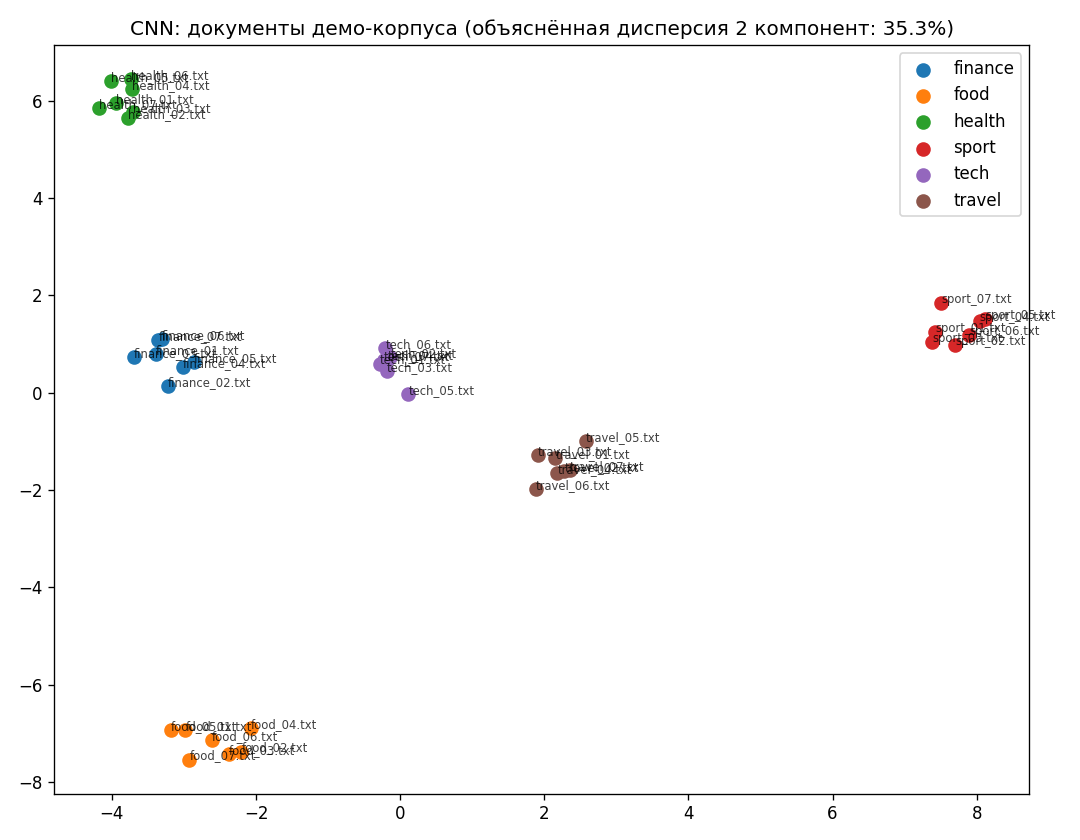

In [13]:
from IPython.display import Image
Image(str(_PROJECT / "lab_4" / "data" / "cnn_2d.png"))

## 12. Выводы и сравнительное описание трёх анализаторов

Три семантических анализатора — **LSA** (`lab_2`), **Doc2Vec** (`lab_3`) и
**CNN/RNN** (`lab_4`) — устроены принципиально по-разному:

| Критерий | LSA (`lab_2`) | Doc2Vec (`lab_3`) | CNN (TextCNN, `lab_4`) | RNN (GRU, `lab_4`) |
| --- | --- | --- | --- | --- |
| Представление документа | TF-IDF + усечённый SVD (латентные темы) | собственный вектор документа (PV-DBOW) | max-pooled карты свёрток | конкатенация скрытых состояний |
| Математический метод | матричное разложение (SVD) | shallow-сеть, SGD, negative sampling | свёрточная сеть, SGD | рекуррентная сеть, SGD |
| Супервизия | нет | нет | да (тема документа) | да (тема документа) |
| Размерность | `k` тем (10) | `dim` (100) | `num_filters × len(kernels)` (192) | `2 × hidden_dim` (128) |
| Интерпретируемость | высокая (тема = список терминов) | средняя (ближайшие слова/документы) | средняя | средняя |
| Новый документ | fold-in проекцией | fold-in (infer_vector) | encode (свёртка + max-pool) | encode (GRU) |
| Ограничение | не учитывает порядок слов | не учитывает порядок слов | фиксированное окно свёртки | обучение медленнее |

На малом демо-корпусе (42 документа) методы дают близкий результат по темам; слабое
место — короткий запрос про «суп/овощи», который на 42 документах не разрешается
ни одним из методов. CNN/GRU, в отличие от LSA/Doc2Vec, дополнительно дают
**классификацию темы** — прямое следствие супервизии. Выбор метода — компромисс
между объяснимостью (LSA), устойчивостью к перефразировке (Doc2Vec) и
обучаемым сквозным представлением с порядковой информацией (CNN/GRU).